In [56]:
import pandas as pd

df_countries = pd.read_csv("Country-data.csv")
df_dict = pd.read_csv("data-dictionary.csv")

df_countries.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [57]:
df_countries.describe()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


In [58]:
df_countries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
country       167 non-null object
child_mort    167 non-null float64
exports       167 non-null float64
health        167 non-null float64
imports       167 non-null float64
income        167 non-null int64
inflation     167 non-null float64
life_expec    167 non-null float64
total_fer     167 non-null float64
gdpp          167 non-null int64
dtypes: float64(7), int64(2), object(1)
memory usage: 13.1+ KB


In [59]:
print("Number of duplicated datapoints: ",df_countries.duplicated().sum(),"\n\nNumber of missing values by column:")
df_countries.isnull().sum()

Number of duplicated datapoints:  0 

Number of missing values by column:


country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

In [60]:
## Create separate DataFrames for labels and features
country_names = df_countries[['country']]
country_features = df_countries.drop('country', axis =1)

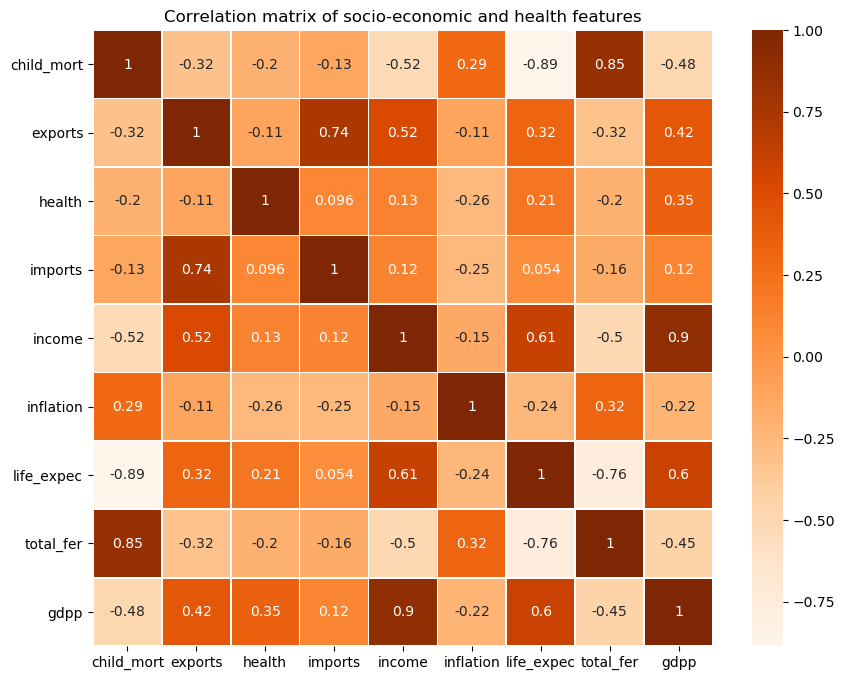

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = country_features.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,       
    cmap="Oranges",      
    linewidths=0.5,
)
plt.title("Correlation matrix of socio-economic and health features")
plt.show()

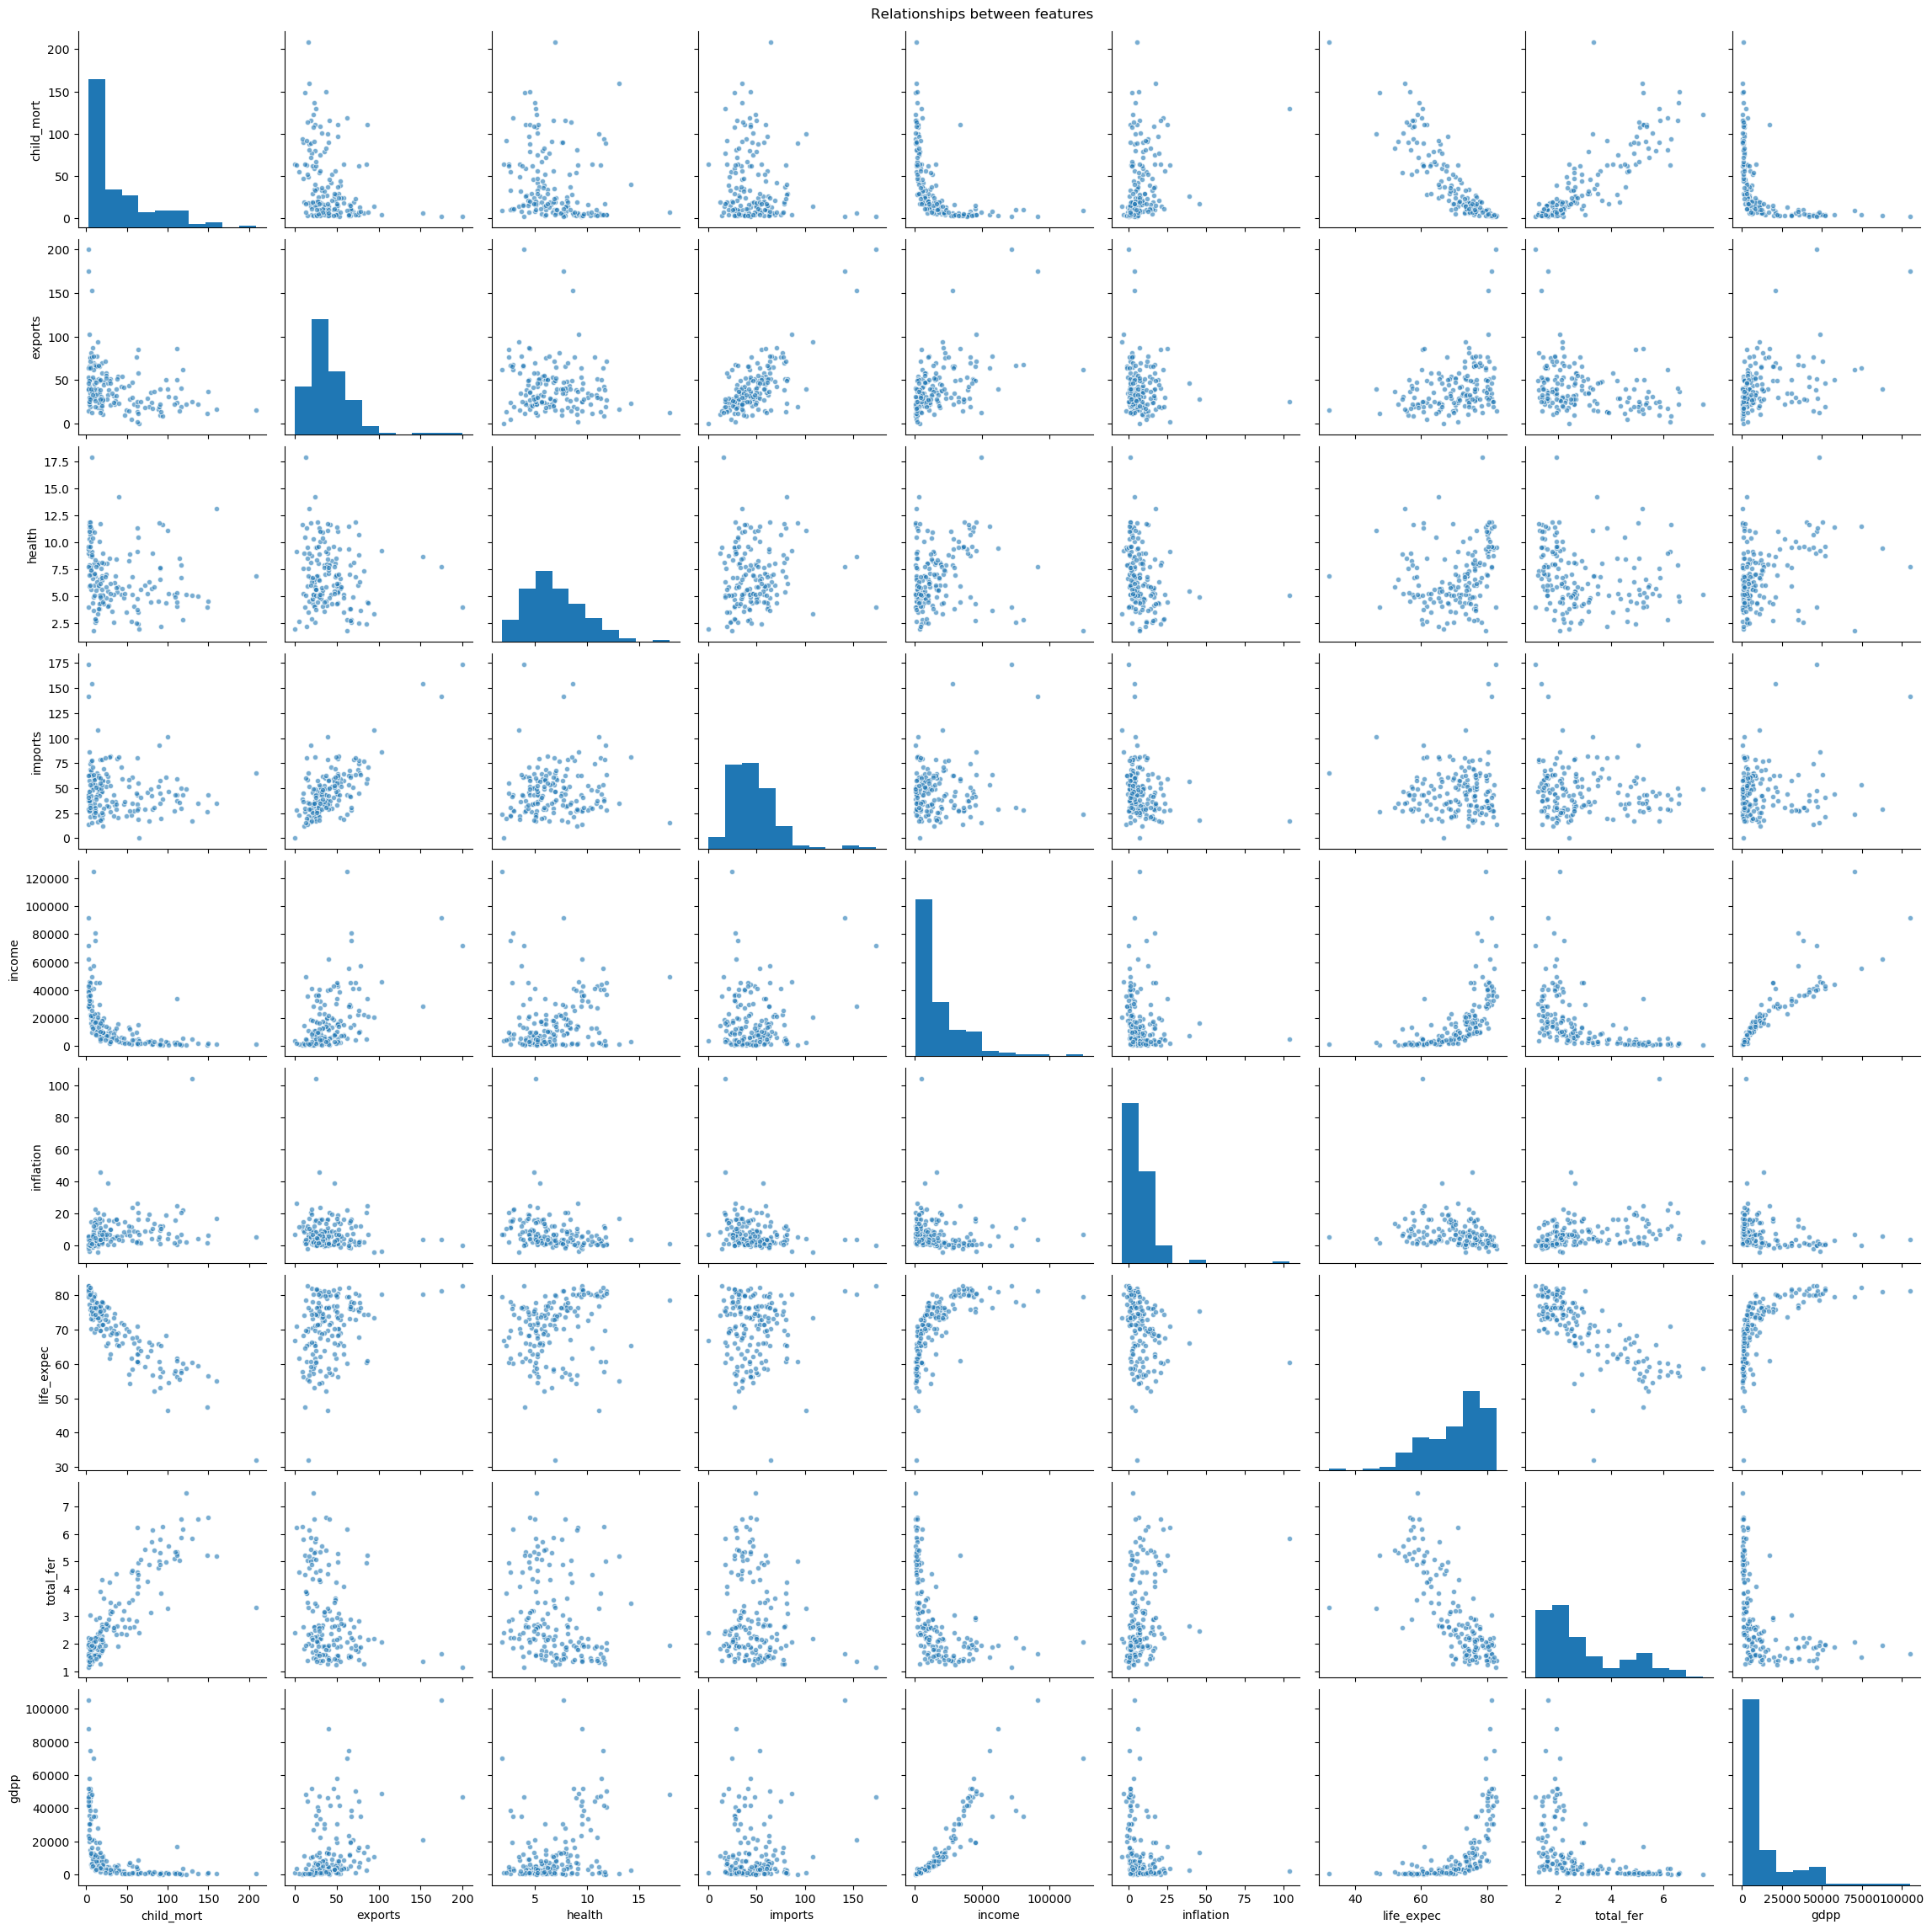

In [62]:
# Histogram and Scatterplot
sns.pairplot(country_features, diag_kind="hist", plot_kws={"alpha": 0.6, "s":20})
plt.suptitle("Relationships between features", y=1.01)
plt.show()

### Observations
Looking at the heatmap, the features aren't independent. From `income`, `gdpp` and `life_expec` all go up together and all go down as `child_mort` and `total_fer`go up. The strongest pairs are `child_mort` and `life_expec` at -0.89, `income` and `gdpp` at +0.90, and `child_mort` and `total_fer` at +0.85. Basically, if Iknow a country's child mortality I can already guess most of its other numbers.`exports` and `imports` correlate with each other (+0.74) but not with much else,so trade seems to be its own separate thing, and `health` and `inflation` are the weakest overall (`health` only gets to +0.35 with `gdpp`). 

### Pairplot 
The Histograms on the diagonal show mostly features are badly skewed. `gdpp`,`income`,`child_mort` and especially `inflation` all pile up at the low end.   

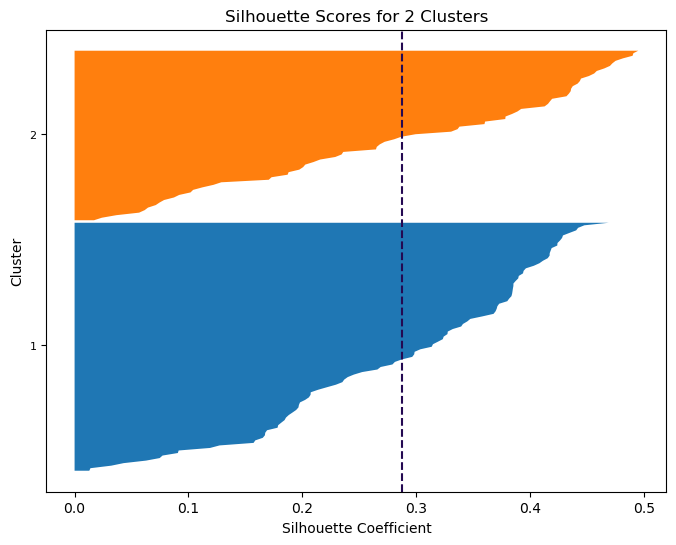

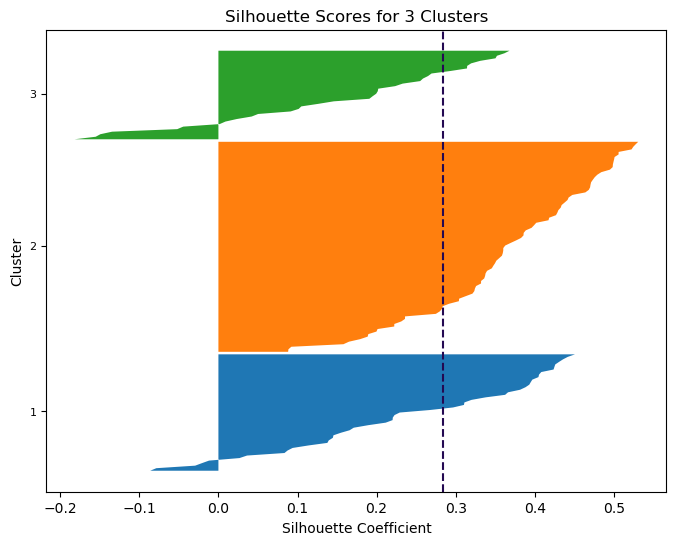

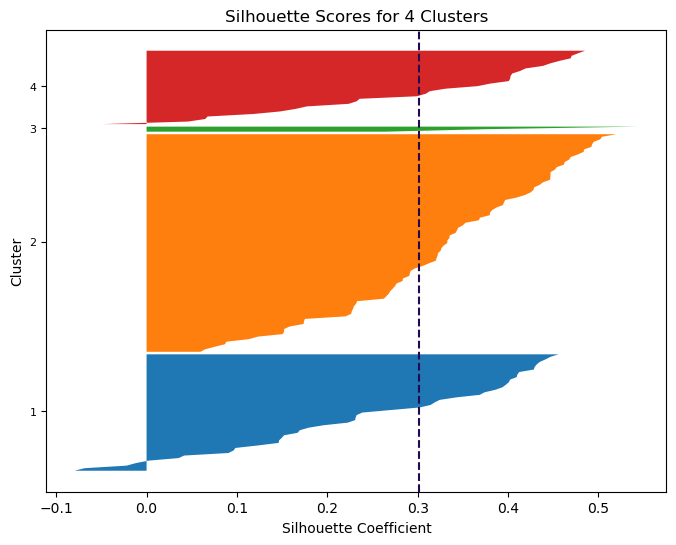

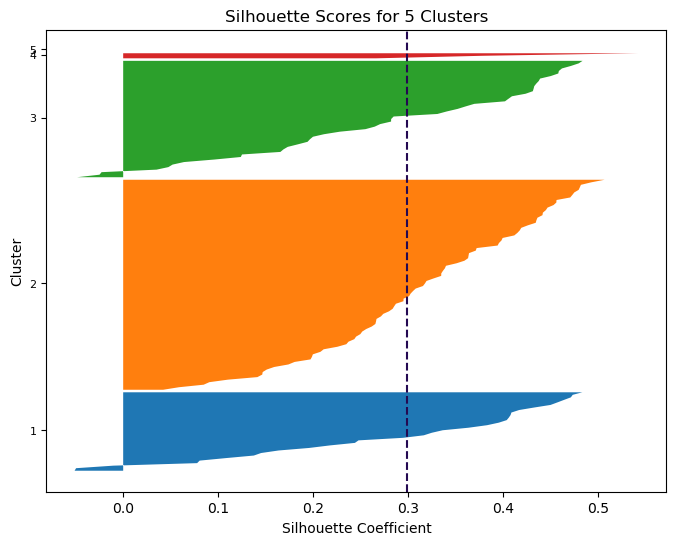

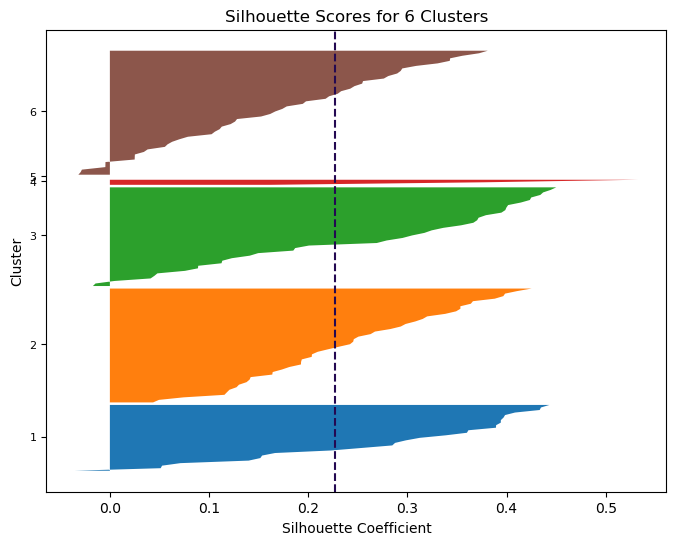

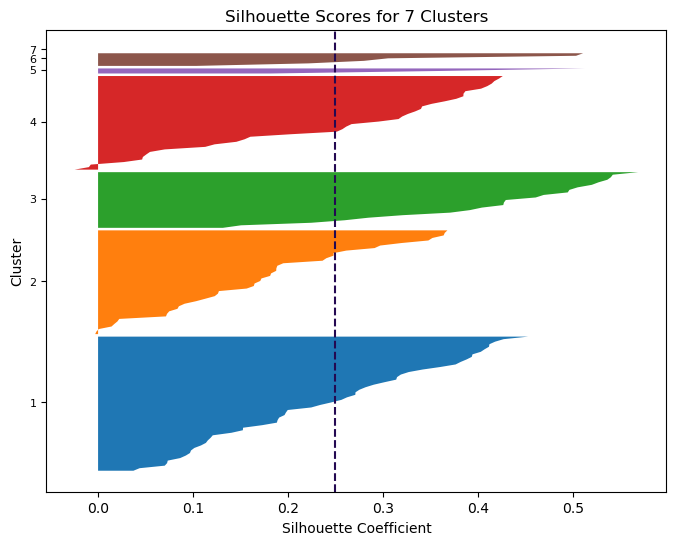

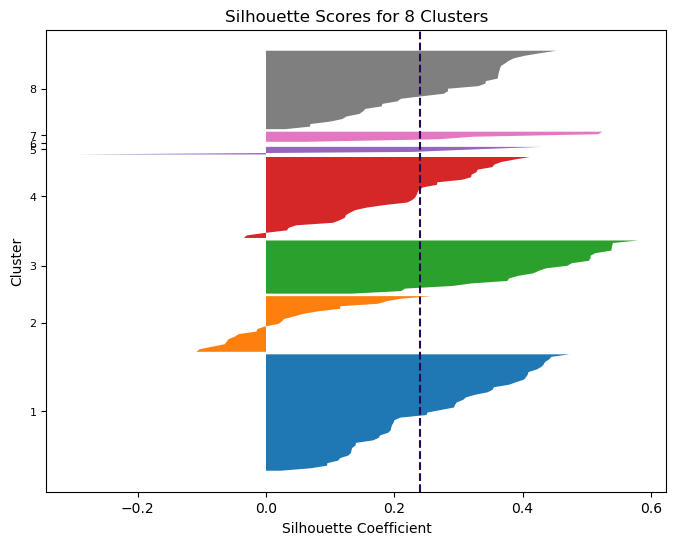

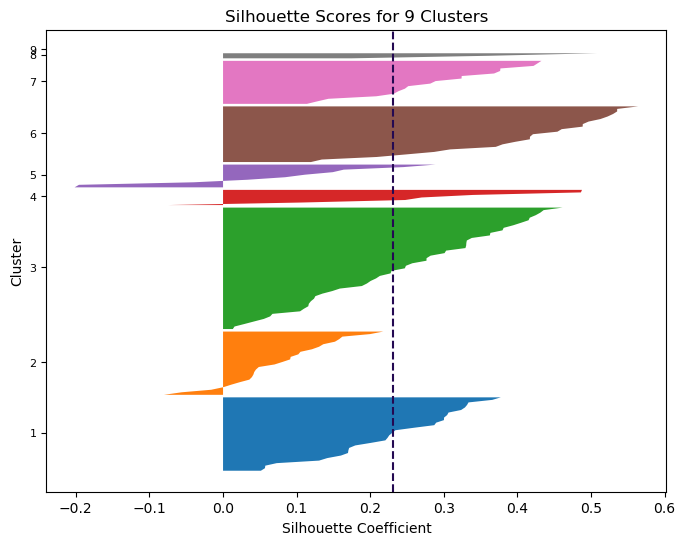

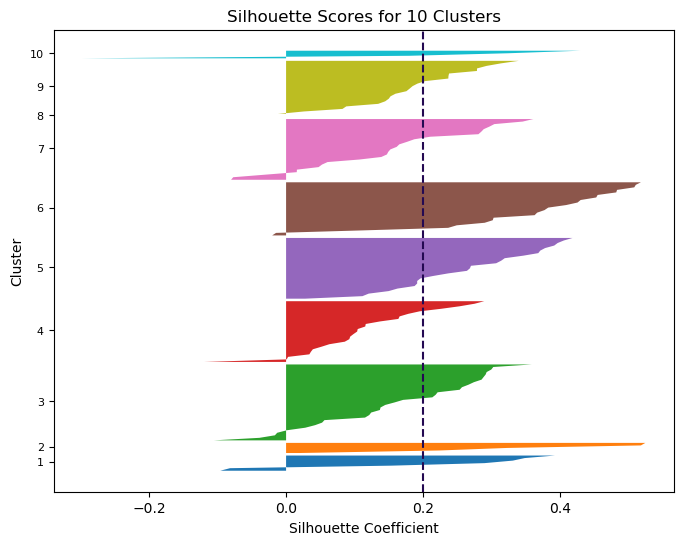

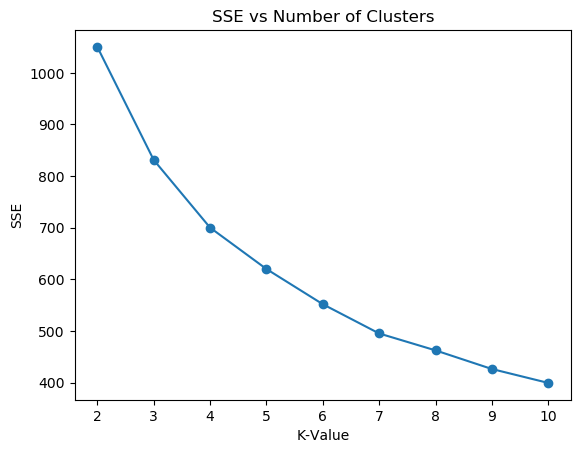

In [69]:
from sklearn.preprocessing import StandardScaler as scaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score as s_score, silhouette_samples as s_samples
import numpy as np

def check_range(k_bounds):
    # Compare parameter types, change return based on input
    if type(k_bounds) == int or type(k_bounds) == float:
        if k_bounds < 2:
            k_bounds = [2]
        else:
            k_bounds = [round(k_bounds)]
    elif type(k_bounds) == tuple:
        k_bounds = list(k_bounds)
        k_bounds.sort()
        if k_bounds[0] < 2:
            k_bounds[0] = 2
    elif type(k_bounds) == list:
        k_bounds.sort()
        if k_bounds[0] < 2:
            k_bounds[0] = 2
    return k_bounds

def get_kmeans(x_var, y_var=None, k_range=2, lamda=0.0001, epoch=500):

    # Determine number of clusters. if unspecified default to 2
    num_clusters = check_range(k_range)

    # Initiallize containers for metrics of different k values
    kmeans_metrics = {
    }
    kmeans_sse = []

    # Run K-Means for k number of clusters
    for k in range(num_clusters[0],num_clusters[-1]+1):
        train_data = scaler().fit_transform(x_var)
        test_model = KMeans(k, random_state=42, max_iter=epoch, tol=lamda).fit(train_data)

        # Add metrics to history
        centroids = test_model.cluster_centers_
        labels = test_model.labels_
        SSE = test_model.inertia_
        silhouette_avg = s_score(train_data,labels)
        silhouette_values = s_samples(train_data, labels)

    # Store model metrics in dictionary
        metrics = {
            "Silhouette Score": silhouette_avg,
            "Silhouette Samples": silhouette_values,
            "SSE": SSE,
            "Centroids": centroids,
            "Labels": labels,
        }

        kmeans_metrics[f"{k} Clusters"] = metrics

    # Plot Silhouette vs Cluster
        prev_cluster_size = 0
        silhouette_plot, axis = plt.subplots(figsize=(8,6))
        for i in range(0,k):
            tick_loc = []
            for n in range(k):
                nth_cluster_values = silhouette_values[labels==n]
                nth_cluster_values.sort()
                nth_cluster_size = len(nth_cluster_values)
                tick_loc.append(nth_cluster_size/2+prev_cluster_size)
                y_upper_bounds = prev_cluster_size + nth_cluster_size
                axis.fill_betweenx(np.arange(prev_cluster_size,y_upper_bounds),0,nth_cluster_values)
                prev_cluster_size += nth_cluster_size
            axis.set_yticks(tick_loc)
            axis.set_yticklabels(np.arange(1,n+2), fontsize=8)
            axis.axvline(silhouette_avg,c=(36/255.0, 9/255.0, 82/255.0),linestyle="--")
            axis .set_title(f"Silhouette Scores for {k} Clusters")
            axis.set_ylabel("Cluster")
            axis.set_xlabel("Silhouette Coefficient")
            plt.show()

        kmeans_sse.append(SSE)
    # Plots Elbow Graph for K-Means
    plt.plot(range(num_clusters[0],num_clusters[-1]+1),kmeans_sse,'o-',)
    plt.title("SSE vs Number of Clusters")
    plt.xlabel("K-Value")
    plt.ylabel("SSE")
    plt.show()

    return kmeans_metrics

# Runs get_kmeans() and stores values in variable
kmeans_metrics = get_kmeans(country_features,k_range=(2,10))

In [131]:
# Compares differences between 3 cluster groupings and 4 cluster groupings
clusters3 = kmeans_metrics["3 Clusters"]
clusters4_labels = []
# print(max(clusters3["Labels"]))
for label in kmeans_metrics["4 Clusters"]["Labels"]:
    if label <=2:
        clusters4_labels.append(label)
    elif label == 3:
        clusters4_labels.append(2)
print(clusters4_labels-clusters3["Labels"],"\n\nTotal differences in classification:",abs(sum(clusters4_labels-clusters3["Labels"])))

[ 0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0] 

Total differences in classification: 3


## Model Selection

Given the problem presented to us, we realized that deciding on which model should be determined by more than just what k-value shows the best results. Since funds are limited, the CEO wants to ensure they are allocated both strategically and effectively. This means that having too few groups could result in resources not being utilized to their full potential, yet having too many would lead to underfunding the projects, not having the resources they needs to launch properly or be sustainable and effective in its goal.

After having run a k-means clustering algorithim checking k values of 2 through 10, we ploted their silhouette graphs along with a plot of each model's sum-squared-error (SSE) vs cluster counts. The elbow plot shows that from 4 to 7 groups, the drop in SSE is relatively low and linear, meaning somewhere in this range would be our ideal number of groups. From the problem statement, we can rule out 6 or 7 clusters as they would cause problems and possibly lead to underfunding. To decide between 4 or 5 clusters, we plotted the silhouette coefficient for each group once for each k-value. Through this, we noticed that although there are less data points with negative Silhouette scores in the 5 cluster model, the fifth grouping has few if any entries and would not be a practical grouping. As such we've decided to use a k value of 4 and have 4 different groupings for the countries.

In [66]:
chosen_model = kmeans_metrics["4 Clusters"]
print(chosen_model)

{'Silhouette Score': 0.301375962376881, 'Silhouette Samples': array([ 0.42935825,  0.48404864,  0.40972131,  0.32433882,  0.39537074,
        0.26806233,  0.49218237,  0.41333988,  0.47033036,  0.37999466,
        0.05960355,  0.11317875,  0.26968586,  0.29711288,  0.446874  ,
        0.31342883,  0.47710582,  0.36871492,  0.4248905 ,  0.31995437,
        0.23190199, -0.07965347,  0.23283441,  0.14777841,  0.43863177,
        0.45589017,  0.34284345,  0.30613655,  0.40088124,  0.46921102,
        0.43506339,  0.38601183,  0.42851955,  0.26528558,  0.45173412,
        0.34473111,  0.23877352,  0.40952626,  0.098287  ,  0.17515036,
        0.39757968,  0.26264536,  0.04573167,  0.06494549,  0.47745304,
        0.45394973,  0.42812429,  0.32244152,  0.50388161,  0.1461373 ,
        0.16714638,  0.27496625,  0.38226353,  0.44667842,  0.41928764,
        0.03552167,  0.31872707,  0.38687825,  0.45693702,  0.23127073,
        0.23573751,  0.48352898,  0.3353536 ,  0.43159346,  0.40217051,
  

figure 1



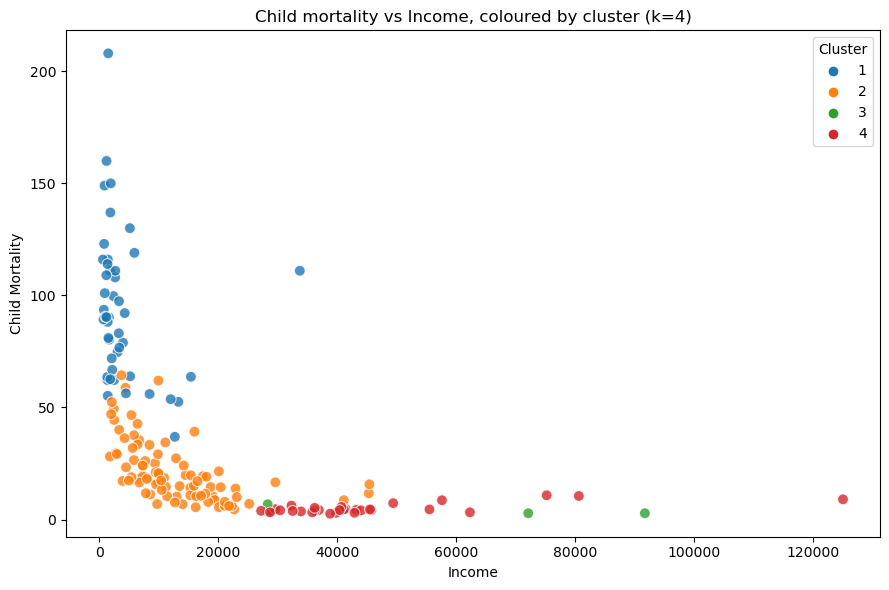

figure 2



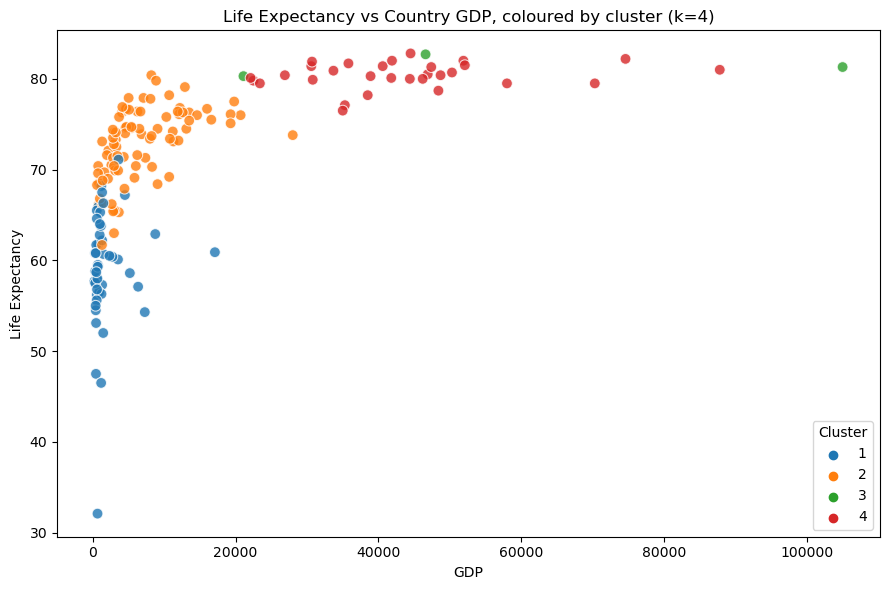

figure 3



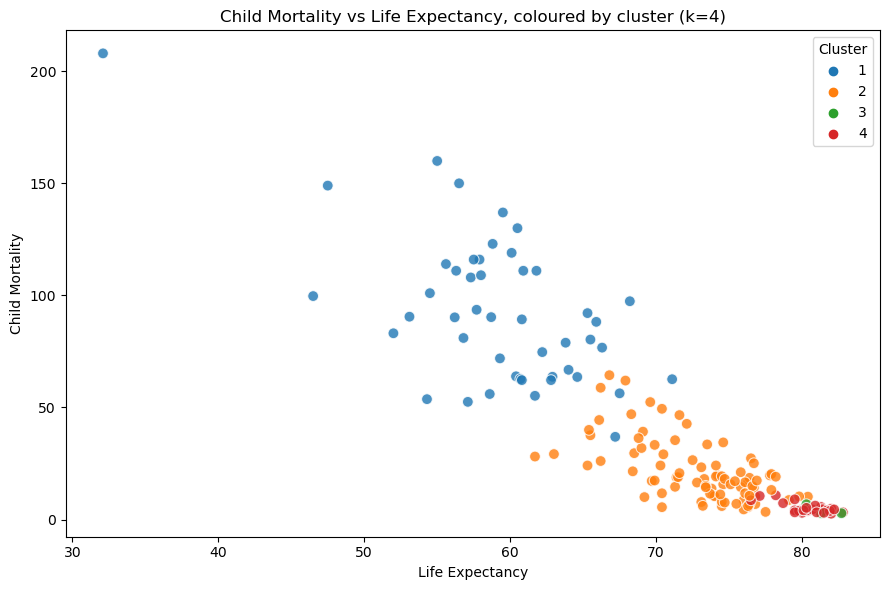

figure 4



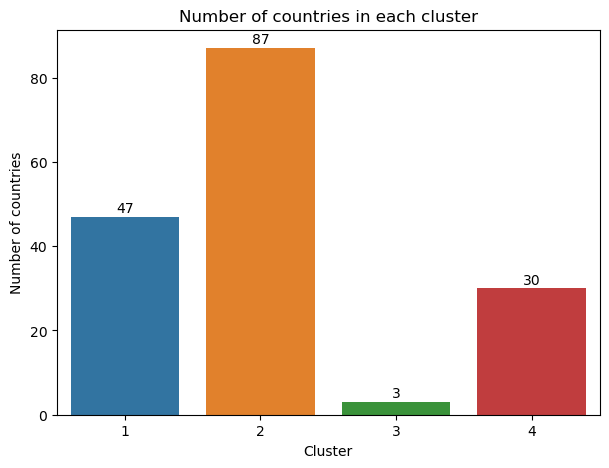

Cluster 1 - 47 countries
Cluster 2 - 87 countries
Cluster 3 - 3 countries
Cluster 4 - 30 countries


,Cluster 1,Cluster 2,Cluster 3,Cluster 4
0,Afghanistan,Albania,Luxembourg,Australia
1,Angola,Algeria,Malta,Austria
2,Benin,Antigua and Barbuda,Singapore,Belgium
3,Botswana,Argentina,-,Brunei
4,Burkina Faso,Armenia,-,Canada
5,Burundi,Azerbaijan,-,Cyprus
6,Cameroon,Bahamas,-,Denmark
7,Central African Republic,Bahrain,-,Finland
8,Chad,Bangladesh,-,France
9,Comoros,Barbados,-,Germany


In [ ]:
# Attach cluster labels back to the original (unscaled) data
df_clustered = df_countries.copy()
df_clustered["Cluster"] = chosen_model['Labels'] + 1

# Profile: average of each feature per cluster
profile = df_clustered.groupby('Cluster')[country_features.columns].mean().round(2)
profile['n_countries'] = df_clustered["Cluster"].value_counts().sort_index()

#Scatterplot
print("figure 1\n")
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_countries, x='income', y='child_mort',
                hue=chosen_model['Labels']+1, palette='tab10', s=60, alpha=0.8)
plt.title('Child mortality vs Income, coloured by cluster (k=4)')
plt.xlabel('Income')
plt.ylabel('Child Mortality')
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print("figure 2\n")
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_countries, x='gdpp', y='life_expec',
                hue=chosen_model['Labels']+1, palette='tab10', s=60, alpha=0.8)
plt.title('Life Expectancy vs Country GDP, coloured by cluster (k=4)')
plt.xlabel('GDP')
plt.ylabel('Life Expectancy')
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print("figure 3\n")
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_countries, x='life_expec', y='child_mort',
                hue=chosen_model['Labels']+1, palette='tab10', s=60, alpha=0.8)
plt.title('Child Mortality vs Life Expectancy, coloured by cluster (k=4)')
plt.xlabel('Life Expectancy')
plt.ylabel('Child Mortality')
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


print("figure 4\n")
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clustered, x="Cluster", palette="tab10")
plt.title("Number of countries in each cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of countries")
for i, count in df_clustered["Cluster"].value_counts().sort_index().items():
    plt.text(i-1, count + 1, str(count), ha="center")
plt.show()

cluster_breakdown = {}
for cluster_number in range(1,5):    # Keep only the rows belonging to this cluster
    countries_in_cluster = df_clustered[df_clustered["Cluster"] == cluster_number]
    print("Cluster", cluster_number, "-", len(countries_in_cluster), "countries")
    cluster_breakdown[f"Cluster {cluster_number}"] = countries_in_cluster["country"].reset_index(drop=True)
    # for country in countries_in_cluster["country"]:
    #     print("   ", country)
    #     print()
df_cluster_breakdown = pd.DataFrame(cluster_breakdown).fillna("-")
df_cluster_breakdown

## Comparison on rankings and real world data

## Our Proposition

Based on our analysis of the data, we determined that Clusters 3 and 4 should be treated as one. The reason for still choosing to use a k-value of 4 is that the SSE is much larger with only 3 groups, and only 3 countries are classified differently if we use the 3 cluster model.

In terms of how to allocate the funds, we suggest implementing a two part program. The first stage is to address child mortality rates, and the second is to help improve life expectancy. As can be seen in figure 3, the countries with reportedly high child mortality rates also record lower life expectancy, and from figures 1 and 2, we can see that the average family income is inversly proportional to child mortality rates and a higher GDP implies a higher life expectancy, although life expectancy does appear to platoe around the range of cluster 3 and 4.

For this reason, we suggest allocating $45 million towards combating child mortality in stage 1, applied in methods such as maternal/infant healthcare, vaccination programs, and treatment of preventable childhood diseases, $40 million in stage 2 to help with improving life expectancy through programs to improve pharmaceutical accesibility, invest in programs to spread health awareness to teach health safety and funding hospitals in poorer regions of the country, $10 million for stage 3 allocated into programs such as doctors without borders and conferences to teach local doctors treatments to common illnesses, and keeping $5 million in a reserve account in case of any event such as a pandemic, epidemic, or other unforseen critical events that may require funding. This way should an emergency occur, the organization would have some room to breathe until they aquire more funding.

Within stage 1 and 2 of the program, funding should be allocated to countries by cluster. Each cluster, after recieving a set amount of funds, is to distribute the funding to each country with a list of proposed  a proportionate amount based on where they lie in comparison to others of the same cluster.

The clusters should recieve their funding as follows:
- Cluster 1 should recieve 50% of the funding to distribute to countries in this grouping. These countries are determined to be in most dire need for assistance as they have both the lowest GDP and average household income by a large factor. This would make it hard for them to implement any of these programs without external support, and families living in these countries are likely too poor to afford getting treatment abroad.

- Cluster 2 should recieve 40% of the funding. From figures 1 and 2, we see that countries in this cluster range from being similar to the high end of cluster 1 to being on the low end of cluster 3 and 4. This demonstrates that while some may not require as much assistance, others do, and so they should recieve an appropriate amount of funding to help push through all the programs we want to implement. Additionally, this cluster should recieve 40% due to having double the amount of countries allocated to it as compared to cluster 1 and cluster 3 or 4.

- Clusters 3 and 4, as mentioned previously, should be treated as part of the same grouping within these programs. These countries have some of the highest life expectancies and lowest child mortality rates. As such, only 10% of the funding is to be allocated to this grouping as while these countries may not need much support, having high average household income does not mean treatment is affordable for everyone, and so while only needing a smaller portion, programs should still be created to support them. Additionally, it may be possible to coordinate with each countries government for additional funds for the programs.